# Bed allocation

A small hospital plans its beds two weeks ahead. Patients are booked in for a known stretch of
nights, each with a specialty, a gender, an age and sometimes equipment they need. Rooms belong to
departments, some rooms take one gender at a time, and the children's ward takes only children. The
question is **which patient gets which bed on which nights, without moving anyone during a stay**.

In this notebook you will:

1. describe the wards and the bookings as Python objects,
2. solve it and draw the plan as a chart with one row per bed,
3. check the result yourself, including a rule that does not mean what its name suggests,
4. change the rules so that required equipment is enforced strictly,
5. close a room and see who pays for it,
6. restart from an existing plan when new admissions arrive.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from collections import Counter
from datetime import date, timedelta

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

from optimaru import bed_allocation as ba
from optimaru.bed_allocation import constraints as rules
from optimaru.bed_allocation.models import BedModel, BedPlanModel, DepartmentModel, RoomModel, StayModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the wards and the bookings

The pydantic models in `optimaru.bed_allocation.models` use readable ids and real dates, and they
are what `solve` and `with_initial_solution` both accept.

| Object | What it holds |
| --- | --- |
| `DepartmentModel` | `specialty_to_priority` (1 is the best fit), `minimum_age`, `maximum_age` |
| `RoomModel` | `department_id`, `capacity`, `gender_limitation`, `equipment` |
| `BedModel` | `room_id` and its position in the room |
| `StayModel` | one booking: patient details, `specialty`, `arrival_date`, `departure_date`, equipment lists, and `bed_id`, the answer |
| `BedPlanModel` | all of the above, plus the score after a solve |

`departure_date` is the last night in the bed, not the morning after, so a stay from Monday to
Tuesday is two nights. A `gender_limitation` of `SAME_GENDER` means patients in the room on the same
night must share a gender, and `ANY_GENDER` means no limit.

Here is a fictional hospital with three departments and 21 beds, and 70 bookings over 14 nights.

In [2]:
FIRST_NIGHT = date(2026, 3, 2)
NIGHTS = 14
SPECIALTIES = ["Cardiology", "Respiratory", "Surgery", "Paediatrics"]

DEPARTMENTS = [
    DepartmentModel(id="MED", name="Medicine", minimum_age=18,
                    specialty_to_priority={"Cardiology": 1, "Respiratory": 1, "Surgery": 3}),
    DepartmentModel(id="SUR", name="Surgery", minimum_age=18,
                    specialty_to_priority={"Surgery": 1, "Cardiology": 3}),
    DepartmentModel(id="CHI", name="Children", maximum_age=17, specialty_to_priority={"Paediatrics": 1}),
]
ROOMS = [  # id, department, beds, gender limitation, equipment
    ("M1", "MED", 2, "SAME_GENDER", ["telemetry", "oxygen"]),
    ("M2", "MED", 2, "SAME_GENDER", ["oxygen"]),
    ("M3", "MED", 4, "SAME_GENDER", ["oxygen"]),
    ("M4", "MED", 1, "ANY_GENDER", ["telemetry", "oxygen"]),
    ("S1", "SUR", 2, "SAME_GENDER", ["oxygen"]),
    ("S2", "SUR", 4, "SAME_GENDER", []),
    ("S3", "SUR", 1, "ANY_GENDER", ["oxygen"]),
    ("C1", "CHI", 3, "ANY_GENDER", ["oxygen"]),
    ("C2", "CHI", 2, "ANY_GENDER", []),
]


def bookings():
    """The same 70 fictional bookings on every call."""
    rng = np.random.default_rng(4)
    stays = []
    for i in range(70):
        specialty = str(rng.choice(SPECIALTIES, p=[0.28, 0.27, 0.28, 0.17]))
        age = int(rng.integers(1, 17)) if specialty == "Paediatrics" else int(rng.integers(19, 92))
        arrival = int(rng.integers(0, NIGHTS - 1))
        nights = int(rng.choice([1, 2, 3, 4, 5, 6], p=[0.1, 0.25, 0.25, 0.2, 0.12, 0.08]))
        required = []
        if specialty == "Cardiology" and rng.random() < 0.5:
            required = ["telemetry"]
        if specialty == "Respiratory" and rng.random() < 0.6:
            required = ["oxygen"]
        wants_tv = rng.random() < 0.3
        room_size = int(rng.choice([1, 2, 4])) if rng.random() < 0.5 else None
        stays.append(StayModel(
            id=f"P{i:02d}",
            patient_name=f"Patient {i}",
            patient_gender=str(rng.choice(["MALE", "FEMALE"])),
            patient_age=age,
            specialty=specialty,
            arrival_date=FIRST_NIGHT + timedelta(days=arrival),
            departure_date=FIRST_NIGHT + timedelta(days=min(arrival + nights, NIGHTS) - 1),
            patient_required_equipment=required,
            patient_preferred_equipment=["television"] if wants_tv else [],
            patient_preferred_maximum_room_capacity=room_size,
        ))
    return stays


def make_problem(closed_rooms=(), extra_stays=()):
    """A fresh, unsolved plan. `solve` returns a new model, but experiments edit the input too."""
    rooms = [
        RoomModel(id=room, name=f"Room {room}", department_id=department, capacity=beds,
                  gender_limitation=limitation, equipment=equipment)
        for room, department, beds, limitation, equipment in ROOMS if room not in closed_rooms
    ]
    beds = [
        BedModel(id=f"{room.id}-{index + 1}", room_id=room.id, index_in_room=index)
        for room in rooms for index in range(room.capacity)
    ]
    return BedPlanModel(departments=DEPARTMENTS, rooms=rooms, beds=beds, stays=[*bookings(), *extra_stays])


def nights_of(stay):
    """Night indices of a stay. `departure_date` is the last night."""
    first = (stay.arrival_date - FIRST_NIGHT).days
    return range(first, (stay.departure_date - FIRST_NIGHT).days + 1)


problem = make_problem()
demand = sum(len(nights_of(stay)) for stay in problem.stays)
print(f"{len(problem.stays)} stays, {len(problem.beds)} beds, {NIGHTS} nights")
print(f"{demand} patient nights booked, {len(problem.beds) * NIGHTS} bed nights available")
print("requiring equipment:", Counter(item for stay in problem.stays for item in stay.patient_required_equipment))

70 stays, 21 beds, 14 nights
224 patient nights booked, 294 bed nights available
requiring equipment: Counter({'oxygen': 11, 'telemetry': 6})


Total demand fits on average. Demand per night shows the peaks, and each department has its own:
adults cannot use the children's beds, nor the reverse.

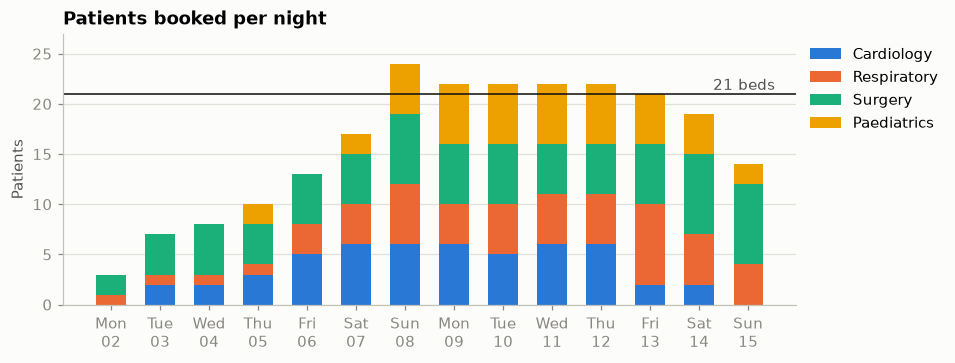

In [3]:
SPECIALTY_COLOR = dict(zip(SPECIALTIES, COLORS))

per_night = {specialty: np.zeros(NIGHTS) for specialty in SPECIALTIES}
for stay in problem.stays:
    for night in nights_of(stay):
        per_night[stay.specialty][night] += 1

night_labels = [(FIRST_NIGHT + timedelta(days=night)).strftime("%a\n%d") for night in range(NIGHTS)]
fig, ax = plt.subplots(figsize=(8.6, 3.2))
bottom = np.zeros(NIGHTS)
for specialty in SPECIALTIES:
    ax.bar(range(NIGHTS), per_night[specialty], bottom=bottom, width=0.6, color=SPECIALTY_COLOR[specialty],
           label=specialty)
    bottom += per_night[specialty]
ax.axhline(len(problem.beds), color="#0b0b0b", linewidth=1)
ax.text(NIGHTS - 0.45, len(problem.beds) + 0.4, f"{len(problem.beds)} beds", ha="right", color=INK)
ax.set_xticks(range(NIGHTS), night_labels)
ax.set(title="Patients booked per night", ylabel="Patients", ylim=(0, max(bottom.max(), len(problem.beds)) + 3))
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 2. Solve it

`ba.solve` runs the compiled search and returns a new `BedPlanModel` with `bed_id` filled in on each
stay, where `None` means the patient got no bed. It stops at `time_limit_seconds`, which defaults to
30, so set it.

The score has three levels, compared in order:

- **hard**: rule breaches, where `0` means the plan is feasible. Two patients in one bed and mixed
  genders in a `SAME_GENDER` room cost 1000 per night, a patient outside a department's age limits
  100 per night, a patient in a gender-limited room of the wrong gender 50 per night, and required
  equipment 50 per night under a rule explained in section 3.
- **medium**: minus the nights of patients with no bed
- **soft**: preferences: a room larger than the patient wanted (8 per night), a specialty the
  department does not offer (10 per night), a lower-priority specialty (10 per night per priority
  step), and missing preferred equipment (50 per night per item)

In [4]:
result = ba.solve(problem, time_limit_seconds=3, random_seed=42)

unplaced = [stay for stay in result.stays if stay.bed_id is None]
print("score    :", result.score_hard, "/", result.score_medium, "/", result.score_soft)
print("no bed   :", len(unplaced), "patients,", sum(len(nights_of(stay)) for stay in unplaced), "nights")

raw = ba.constraint_costs(result.to_core())
print("\nraw cost by constraint, where anything is left:")
for name, entry in raw.items():
    total = sum(entry["costs"])
    if total:
        print(f"  {name}: {total:g} x weight {entry['weight']:g}")

score    : 0 / -7 / -5018
no bed   : 4 patients, 7 nights

raw cost by constraint, where anything is left:
  preferred_maximum_room_capacity: 26 x weight 8
  department_specialty: 16 x weight 10
  department_specialty_not_first_priority: 80 x weight 10
  preferred_patient_equipment: 77 x weight 50


### The plan, bed by bed

Each row is a bed, grouped by room and department, and each block is one patient's stay. This is the
sheet a bed manager works from. Patients with no bed sit in their own rows at the bottom. Night
gridlines fall on the block edges, so a block covers exactly the nights the patient is in that bed.

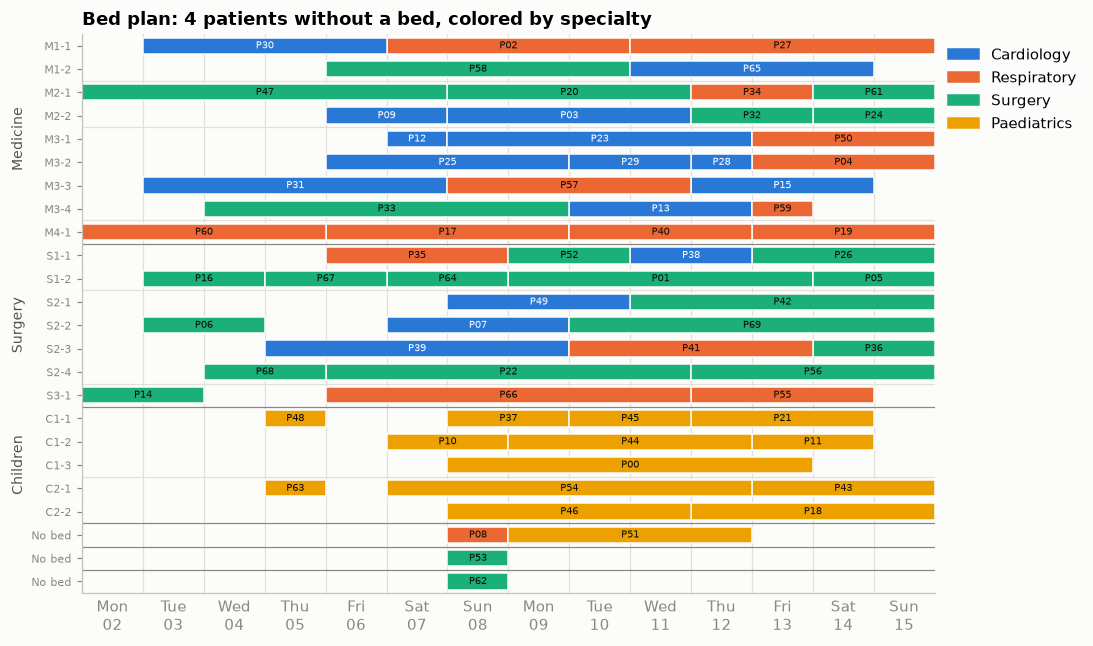

In [5]:
def bed_rows(plan):
    """Rows from the top: beds by department and room, then rows for patients without a bed."""
    room_of = {room.id: room for room in plan.rooms}
    rows = sorted(plan.beds, key=lambda bed: (
        [d.id for d in plan.departments].index(room_of[bed.room_id].department_id),
        bed.room_id,
        bed.index_in_room,
    ))
    return rows, room_of


def no_bed_lanes(plan):
    """Put patients without a bed in as few rows as possible, with no overlap inside a row."""
    lanes = []
    waiting = sorted((stay for stay in plan.stays if stay.bed_id is None), key=lambda stay: stay.arrival_date)
    for stay in waiting:
        for lane in lanes:
            if lane[-1].departure_date < stay.arrival_date:
                lane.append(stay)
                break
        else:
            lanes.append([stay])
    return lanes


def draw_plan(ax, plan, color_of, text_color_of):
    beds, room_of = bed_rows(plan)
    lanes = no_bed_lanes(plan)
    row_of = {bed.id: row for row, bed in enumerate(beds)}

    def draw_stay(stay, row):
        first = nights_of(stay)[0]
        length = len(nights_of(stay))
        ax.barh(row, length, left=first, height=0.7, color=color_of(stay), edgecolor="#fcfcfb", linewidth=1)
        ax.text(first + length / 2, row, stay.id, ha="center", va="center", fontsize=6.5, color=text_color_of(stay))

    for stay in plan.stays:
        if stay.bed_id is not None:
            draw_stay(stay, row_of[stay.bed_id])
    for offset, lane in enumerate(lanes):
        for stay in lane:
            draw_stay(stay, len(beds) + offset)

    row_labels = [bed.id for bed in beds] + ["No bed"] * len(lanes)
    ax.set_yticks(range(len(row_labels)), row_labels, fontsize=7.5)
    ax.set_xticks(range(NIGHTS), [""] * NIGHTS)
    ax.set_xticks(np.arange(NIGHTS) + 0.5, night_labels, minor=True)
    ax.tick_params(axis="x", which="minor", length=0)
    ax.tick_params(axis="x", which="major", length=0)
    ax.set(xlim=(0, NIGHTS), ylim=(len(row_labels) - 0.5, -0.5))
    ax.grid(True, axis="x")

    for row in range(1, len(row_labels)):
        previous = room_of[beds[row - 1].room_id] if row - 1 < len(beds) else None
        current = room_of[beds[row].room_id] if row < len(beds) else None
        if previous is None or current is None or previous.id != current.id:
            same_department = previous and current and previous.department_id == current.department_id
            ax.axhline(row - 0.5, color="#e1e0d9" if same_department else "#898781", linewidth=0.8)
    names = {department.id: department.name for department in plan.departments}
    for department in plan.departments:
        rows = [row for row, bed in enumerate(beds) if room_of[bed.room_id].department_id == department.id]
        if rows:
            ax.text(-0.075, np.mean(rows), names[department.id], transform=ax.get_yaxis_transform(), rotation=90,
                    ha="center", va="center", fontsize=9, color=INK)


fig, ax = plt.subplots(figsize=(10, 6.6))
draw_plan(ax, result, lambda stay: SPECIALTY_COLOR[stay.specialty],
          lambda stay: "white" if stay.specialty == "Cardiology" else "#0b0b0b")
ax.set_title(f"Bed plan: {len(unplaced)} patients without a bed, colored by specialty")
ax.legend(handles=[Patch(color=color, label=name) for name, color in SPECIALTY_COLOR.items()],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### The same plan by gender

The same chart, now colored by gender. In a `SAME_GENDER` room, all beds taken on one night should
show one color: follow a night column down through M1, M2, M3, S1 and S2 to see it. Rooms M4, S3, C1
and C2 have no limit.

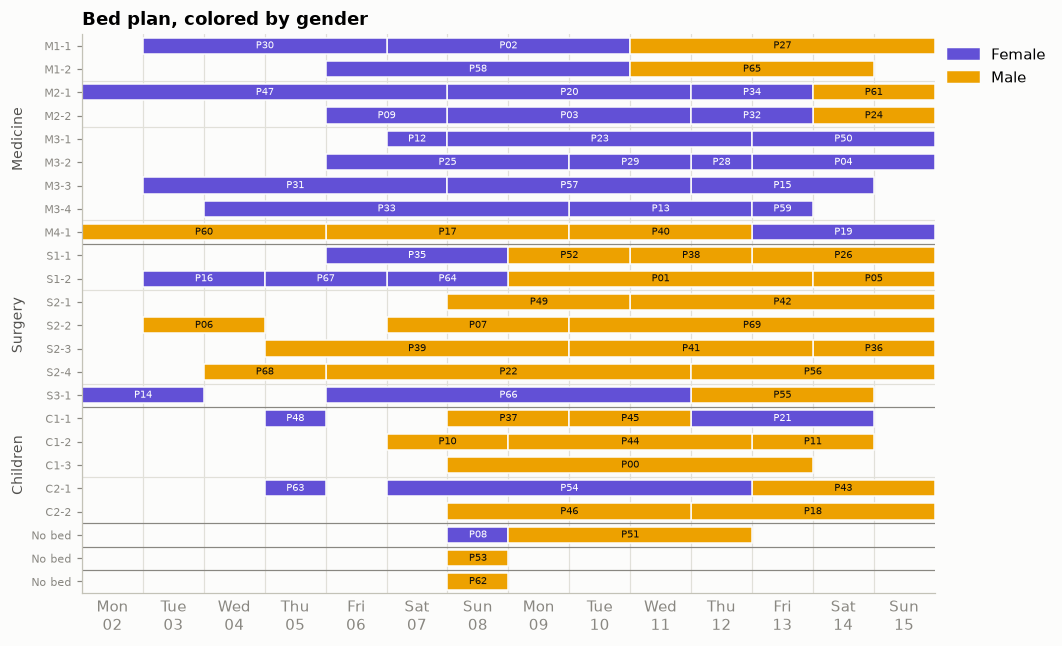

In [6]:
GENDER_COLOR = {"FEMALE": COLORS[6], "MALE": COLORS[3]}

fig, ax = plt.subplots(figsize=(10, 6.6))
draw_plan(ax, result, lambda stay: GENDER_COLOR[stay.patient_gender],
          lambda stay: "white" if stay.patient_gender == "FEMALE" else "#0b0b0b")
ax.set_title("Bed plan, colored by gender")
ax.legend(handles=[Patch(color=color, label=name.capitalize()) for name, color in GENDER_COLOR.items()],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

This recomputes the hard rules from `bed_id` and the input, with no solver code.

The last check looks for a rule that does not do what its name suggests. `required_patient_equipment`
counts only when a room has **some but not all** of what the patient requires, and it then charges
by the items the room has. A room with **none** of the required equipment costs nothing, so for a
patient who requires one item the rule can never fire. A score of hard `0` does not promise that
patients got their equipment, and this check asks the direct question.

In [7]:
def equipment_shortfalls(plan):
    """Placed patients whose room lacks something they require."""
    room_of_bed = {bed.id: bed.room_id for bed in plan.beds}
    equipment = {room.id: set(room.equipment) for room in plan.rooms}
    return [
        stay for stay in plan.stays
        if stay.bed_id is not None
        and not set(stay.patient_required_equipment) <= equipment[room_of_bed[stay.bed_id]]
    ]


room_of_bed = {bed.id: bed.room_id for bed in result.beds}
room_by_id = {room.id: room for room in result.rooms}
department_by_id = {department.id: department for department in result.departments}

patients_in_bed = Counter()
genders_in_room = {}
outside_ages = []
for stay in result.stays:
    if stay.bed_id is None:
        continue
    room = room_by_id[room_of_bed[stay.bed_id]]
    department = department_by_id[room.department_id]
    too_young = department.minimum_age is not None and stay.patient_age < department.minimum_age
    too_old = department.maximum_age is not None and stay.patient_age > department.maximum_age
    if too_young or too_old:
        outside_ages.append(stay.id)
    for night in nights_of(stay):
        patients_in_bed[stay.bed_id, night] += 1
        if room.gender_limitation == "SAME_GENDER":
            genders_in_room.setdefault((room.id, night), set()).add(stay.patient_gender)

short = equipment_shortfalls(result)
print("one patient per bed per night:", all(count == 1 for count in patients_in_bed.values()))
print("one gender per limited room  :", all(len(genders) == 1 for genders in genders_in_room.values()))
print("patients outside age limits  :", outside_ages)
print(f"hard score                   : {result.score_hard}")
print(f"patients missing required kit: {len(short)}, "
      f"{sum(len(nights_of(stay)) for stay in short)} nights")
for stay in short:
    print(f"  {stay.id} needs {stay.patient_required_equipment}, in room {room_of_bed[stay.bed_id]} "
          f"with {room_by_id[room_of_bed[stay.bed_id]].equipment}")

one patient per bed per night: True
one gender per limited room  : True
patients outside age limits  : []
hard score                   : 0
patients missing required kit: 6, 22 nights
  P07 needs ['telemetry'], in room S2 with []
  P13 needs ['telemetry'], in room M3 with ['oxygen']
  P25 needs ['telemetry'], in room M3 with ['oxygen']
  P39 needs ['telemetry'], in room S2 with []
  P41 needs ['oxygen'], in room S2 with []
  P49 needs ['telemetry'], in room S2 with []


Any patient listed on the last lines above is a real gap in the plan even though the score is
feasible: that person needs equipment the room does not have. The next section closes it.

## 4. Change the rules, not the solver

Every rule is a plugin. `ba.list_constraints()` shows what ships with this use case, and
`constraints` takes the list to score. Only listed constraints count. `weight` scales a rule, `hard`
moves it between hard and soft, and `exponent` shapes large violations. Leave
`assign_every_patient_to_a_bed` as it is: its medium level cannot be set with `hard`.

`preferred_patient_equipment` does count every missing item, so it can stand in for the strict rule.
Copy each patient's required equipment into the preferred list, and flip the constraint to hard.
This variant drops the television wishes, which would otherwise turn hard too.

same_bed_in_same_night
female_in_male_room
male_in_female_room
department_minimum_age
department_maximum_age
required_patient_equipment
assign_every_patient_to_a_bed
preferred_maximum_room_capacity
department_specialty
department_specialty_not_first_priority
preferred_patient_equipment
different_gender_in_same_gender_room_in_same_night


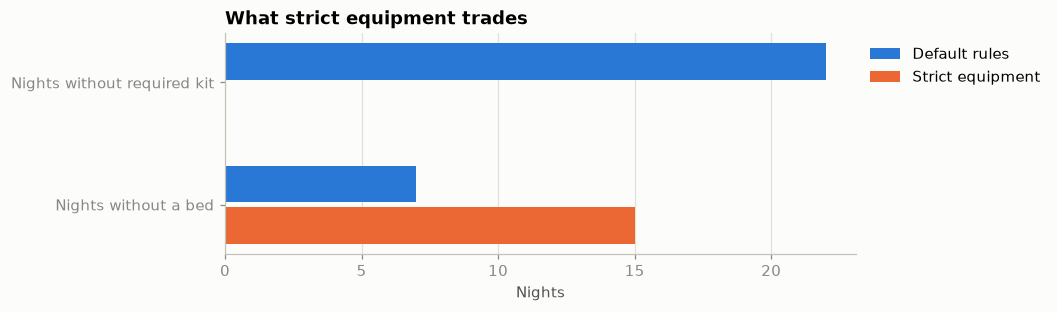

default: 0 / -7 / -5018, 6 patients short of kit
strict : 0 / -15 / -996, 0 patients short of kit


In [8]:
for name in ba.list_constraints():
    print(name)

strict_rules = [rule for rule in rules.get_constraints() if rule.name != "preferred_patient_equipment"]
strict_rules.append(rules.PreferredPatientEquipment(hard=True))


def strict_problem():
    strict = make_problem()
    for stay in strict.stays:
        stay.patient_preferred_equipment = list(stay.patient_required_equipment)
    return strict


strict_result = ba.solve(strict_problem(), time_limit_seconds=3, random_seed=42, constraints=strict_rules)


def nights_without_bed(plan):
    return sum(len(nights_of(stay)) for stay in plan.stays if stay.bed_id is None)


def nights_short_of_kit(plan):
    return sum(len(nights_of(stay)) for stay in equipment_shortfalls(plan))


labels = ["Nights without required kit", "Nights without a bed"]
default_values = [nights_short_of_kit(result), nights_without_bed(result)]
strict_values = [nights_short_of_kit(strict_result), nights_without_bed(strict_result)]

y = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(7.4, 2.6))
ax.barh(y - 0.17, default_values, height=0.3, color=COLORS[0], label="Default rules")
ax.barh(y + 0.17, strict_values, height=0.3, color=COLORS[1], label="Strict equipment")
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set(title="What strict equipment trades", xlabel="Nights")
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"default: {result.score_hard} / {result.score_medium} / {result.score_soft}, "
      f"{len(equipment_shortfalls(result))} patients short of kit")
print(f"strict : {strict_result.score_hard} / {strict_result.score_medium} / {strict_result.score_soft}, "
      f"{len(equipment_shortfalls(strict_result))} patients short of kit")

Under the strict rule a patient who needs equipment takes a bed in a room that has it, or no bed at
all, so the chart shows the real capacity of the equipped rooms. Soft scores are not comparable here,
because the television wishes are gone from the strict run.

## 5. Close a room

Rooms close for cleaning, repairs and staff shortages. Here the plan is solved again with one room
out. The closed room's department matters: children can only use the children's rooms, so a closure
there has nowhere to overflow, while adult patients can spill between Medicine and Surgery.

All rooms open : score 0 / -7 / -5018, 7 nights without a bed
C2 closed      : score 0 / -20 / -4430, 20 nights without a bed
S1 closed      : score 0 / -22 / -4628, 22 nights without a bed
S2 closed      : score 0 / -39 / -4112, 39 nights without a bed
M3 closed      : score 0 / -42 / -3904, 42 nights without a bed


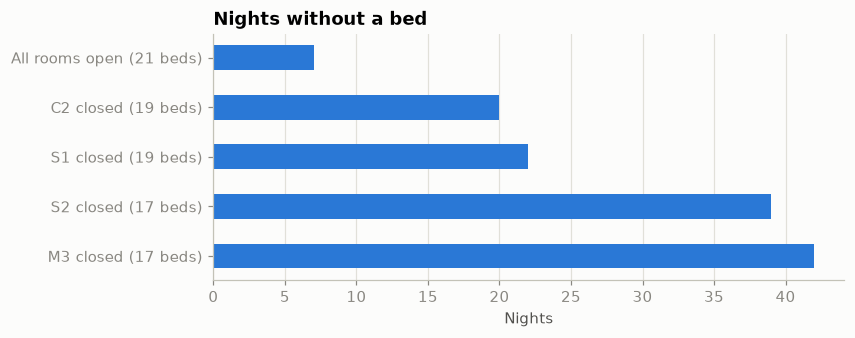

In [9]:
closures = [(), ("C2",), ("S1",), ("S2",), ("M3",)]
names, no_bed_nights = [], []
for closed in closures:
    candidate = ba.solve(make_problem(closed_rooms=closed), time_limit_seconds=3, random_seed=42)
    label = f"{closed[0]} closed" if closed else "All rooms open"
    names.append(f"{label} ({len(candidate.beds)} beds)")
    no_bed_nights.append(nights_without_bed(candidate))
    print(f"{label:15s}: score {candidate.score_hard} / {candidate.score_medium} / {candidate.score_soft}, "
          f"{nights_without_bed(candidate)} nights without a bed")

fig, ax = plt.subplots(figsize=(7.4, 2.9))
ax.barh(names, no_bed_nights, height=0.5, color=COLORS[0])
ax.invert_yaxis()
ax.set(title="Nights without a bed", xlabel="Nights")
ax.grid(True, axis="x")
plt.show()

## 6. Restart from an existing plan

`with_initial_solution` takes the problem and a model that `solve` returned, or that model as JSON,
and returns a copy to solve. Stays are matched by id. A stay left out of the solution, and a stay
with no bed in it, go through the construction again.

**Change `random_seed` between rounds.** Under a fixed `step_count_limit`, the same start with the same
seed repeats the same search and finds nothing new. The chart gives each round 200 steps, an amount
that does not depend on the clock, from a construction-only plan. `time_limit_seconds=0` runs the
construction and no search.

same seed 5: [46, 46, 46, 46, 46, 46, 46, 46, 46]
same seed 6: [46, 43, 43, 43, 43, 43, 43, 43, 43]
same seed 7: [46, 46, 46, 46, 46, 46, 46, 46, 46]
new seeds from 100: [46, 46, 46, 46, 42, 42, 41, 41, 41]
new seeds from 200: [46, 46, 46, 46, 41, 37, 37, 34, 34]
new seeds from 300: [46, 46, 43, 40, 35, 35, 35, 35, 34]


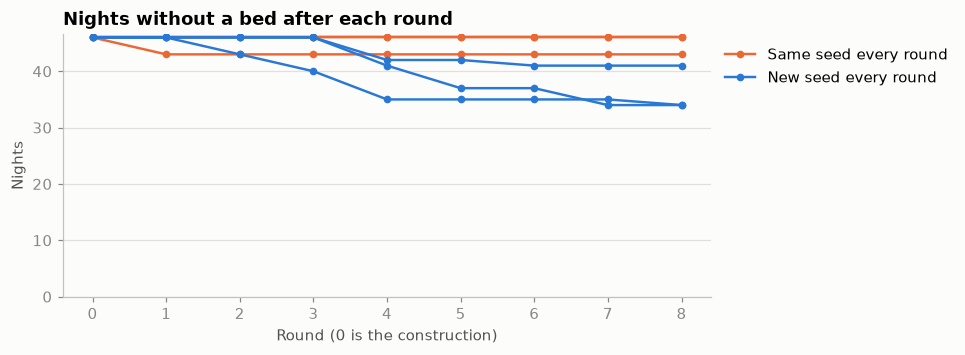

In [10]:
def run_rounds(seeds, steps=200):
    """Nights without a bed after each short round, every round continuing from the previous plan."""
    plan = ba.solve(make_problem(), time_limit_seconds=0, random_seed=1)
    history = [nights_without_bed(plan)]
    for seed in seeds:
        config = ba.SolverConfig()
        config.step_count_limit = steps
        config.random_seed = seed
        plan = ba.solve(ba.with_initial_solution(make_problem(), plan), config=config)
        history.append(nights_without_bed(plan))
    return history


ROUNDS = 8
rounds = range(ROUNDS + 1)
fig, ax = plt.subplots(figsize=(7.6, 3.1))
for run, seed in enumerate([5, 6, 7]):
    same_seed = run_rounds([seed] * ROUNDS)
    ax.plot(rounds, same_seed, color=COLORS[1], linewidth=1.6, marker="o", markersize=4,
            label="Same seed every round" if run == 0 else None)
    print(f"same seed {seed}:", same_seed)
for run, first_seed in enumerate([100, 200, 300]):
    new_seed = run_rounds(range(first_seed, first_seed + ROUNDS))
    ax.plot(rounds, new_seed, color=COLORS[0], linewidth=1.6, marker="o", markersize=4,
            label="New seed every round" if run == 0 else None)
    print(f"new seeds from {first_seed}:", new_seed)
ax.set(title="Nights without a bed after each round", xlabel="Round (0 is the construction)",
       ylabel="Nights", ylim=(0, None))
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### New admissions

Five patients are booked after the plan went out, and everyone else has already been told their
bed. This use case has no way to pin a stay, and the score has no term for keeping a plan, so a
restart can still move people. What matters is how many, against how many nights go without a bed.
Bed ids are stable between runs, so moves can be counted directly.

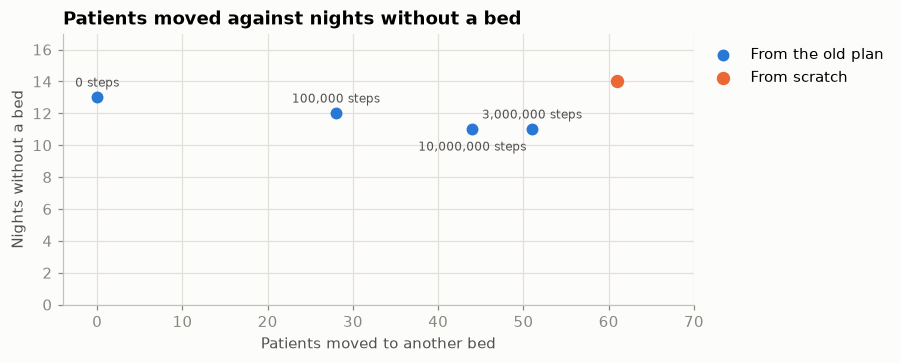

patients with a bed in the old plan: 66
         0 steps: score 0 / -13 / -5118, 0 patients moved
   100,000 steps: score 0 / -12 / -4876, 28 patients moved
 3,000,000 steps: score 0 / -11 / -5090, 51 patients moved
10,000,000 steps: score 0 / -11 / -4894, 44 patients moved
from scratch: score 0 / -14 / -4914, 61 patients moved


In [11]:
def admission(index, arrival, nights, specialty, gender, age, required=()):
    first = FIRST_NIGHT + timedelta(days=arrival)
    return StayModel(
        id=f"N{index}", patient_name=f"New patient {index}", patient_gender=gender, patient_age=age,
        specialty=specialty, arrival_date=first, departure_date=first + timedelta(days=nights - 1),
        patient_required_equipment=list(required),
    )


new_stays = [
    admission(0, 2, 3, "Surgery", "FEMALE", 54),
    admission(1, 3, 2, "Cardiology", "MALE", 71, ["telemetry"]),
    admission(2, 3, 3, "Respiratory", "FEMALE", 63, ["oxygen"]),
    admission(3, 4, 2, "Paediatrics", "MALE", 9),
    admission(4, 4, 3, "Surgery", "MALE", 47),
]
updated = make_problem(extra_stays=new_stays)

def moved_patients(old, new):
    beds = {stay.id: stay.bed_id for stay in new.stays}
    return sum(stay.bed_id is not None and beds[stay.id] != stay.bed_id for stay in old.stays)


def restart(steps):
    """Continue from the old plan for a fixed number of steps. 0 places the new patients and stops."""
    config = ba.SolverConfig()
    config.random_seed = 7
    if steps:
        config.step_count_limit = steps
    else:
        config.spent_limit_seconds = 0
    return ba.solve(ba.with_initial_solution(updated, result), config=config)


budgets = [0, 100_000, 3_000_000, 10_000_000]
outcomes = [restart(steps) for steps in budgets]
cold = ba.solve(updated, time_limit_seconds=3, random_seed=7)

fig, ax = plt.subplots(figsize=(7.4, 3.2))
moved = [moved_patients(result, plan) for plan in outcomes]
no_bed = [nights_without_bed(plan) for plan in outcomes]
ax.scatter(moved, no_bed, s=46, color=COLORS[0], zorder=3, label="From the old plan")
for steps, x, y_value, lift in zip(budgets, moved, no_bed, [7, 7, 7, -14]):
    ax.annotate(f"{steps:,} steps", (x, y_value), xytext=(0, lift), textcoords="offset points", ha="center",
                fontsize=8, color=INK)
ax.scatter(moved_patients(result, cold), nights_without_bed(cold), s=60, color=COLORS[1], zorder=3,
           label="From scratch")
ax.set(title="Patients moved against nights without a bed", xlabel="Patients moved to another bed",
       ylabel="Nights without a bed", xlim=(-4, len(result.stays)), ylim=(0, max(*no_bed, nights_without_bed(cold)) + 3))
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(True)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"patients with a bed in the old plan: {sum(stay.bed_id is not None for stay in result.stays)}")
for steps, plan, x in zip(budgets, outcomes, moved):
    print(f"{steps:10,d} steps: score {plan.score_hard} / {plan.score_medium} / {plan.score_soft}, {x} patients moved")
print(f"from scratch: score {cold.score_hard} / {cold.score_medium} / {cold.score_soft}, "
      f"{moved_patients(result, cold)} patients moved")

The step budget is the control here. With no search, nobody moves and the new patients take what is
left. A step is one tried move, and a plan that is already good takes far more steps to improve than
a rough one, so these budgets are much larger than in the rounds above. Pick the point your ward can
live with, and tell the staff how many beds change.


## Next steps

- `use-cases/bed-allocation/README.md` covers the solver settings and how to add your own moves and
  constraints in C++.
- For assigning people to shifts rather than patients to beds, see `employee-scheduling.ipynb`.